# PhageLysClass — Benchmarking and final-model panel

This notebook builds the **single integrated benchmarking figure** used for the predictive-modeling results.

**v4 layout revision:** enlarged publication typography, higher panels, more breathing room for heatmaps/legends, and clearly legible numeric annotations. All source data, transformations, labels, plots, metrics, and colors follow v3.

Final layout:

| Row | Column 1 | Column 2 | Column 3 |
|---|---|---|---|
| 1 | **A** Task performance distributions | **D** Robustness selection | **G** Binary confusion matrix |
| 2 | **B** Representation performance distributions | **E** Ensemble gains | **H** Multiclass confusion matrix |
| 3 | **C** Generalization effects | **F** Frozen recipes | **I** ROC curves |

Design decisions:
- no subplot titles;
- no colored background blocks;
- Figure 2 palette and typography;
- histogram + KDE for performance distributions;
- the Precision–Recall panel is omitted;
- the final-model characterization occupies one single right-hand column;
- confusion matrices show the strict `R30/S30` final global binary core and functional multiclass core;
- ROC curves combine the final binary models in one plot.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sns.set_theme(
    context="paper",
    style="white",
    font="DejaVu Sans",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#7F93A8",
        "xtick.color": "#3F5061",
        "ytick.color": "#3F5061",
        "axes.labelcolor": "#31465A",
        "text.color": "#31465A",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

mpl.rcParams.update({
    "font.size": 15.0,
    "axes.labelsize": 16.0,
    "xtick.labelsize": 13.5,
    "ytick.labelsize": 13.5,
    "legend.fontsize": 12.8,
    "axes.titlesize": 16.0,
    "savefig.facecolor": "white",
})

COLORS = {
    "P_core": "#4F81BD",
    "P core": "#4F81BD",
    "N_easy": "#9BB7D3",
    "N_hard": "#5FA8A0",
    "Unknown": "#B8B8D6",
    "Negative": "#8EABC8",
    "Endolysin": "#4F81BD",
    "DPO": "#7E9FC7",
    "VAL": "#65B5A6",
    "E2 composition": "#8FB1D5",
    "E3 physicochemical": "#72B7B2",
    "E2+E3 combined": "#507FB4",
    "ESM2-T6": "#A89CC8",
    "ESM2-T30": "#6F5FA8",
}

DIVERGING_CMAP = sns.diverging_palette(
    245, 15, s=70, l=65, center="light", as_cmap=True
)
LETTER_COLOR = "#315A84"

# Publication readability controls (unchanged figure palette and data)
FIGURE_WIDTH = 18.0
FIGURE_HEIGHT = 16.0
PANEL_LETTER_SIZE = 25
HEATMAP_NUMBER_SIZE = 13.5
CONFUSION_NUMBER_SIZE = 14.5
COLORBAR_TICK_SIZE = 12.5
COLORBAR_LABEL_SIZE = 14


DISPLAY_NAMES = {
    "P_core": "P core",
    "N_easy": "N easy",
    "N_hard": "N hard",
    "N_mixed": "N mixed",
    "Unknown": "Unknown",
    "Negative": "Negative",
}

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

TASK_NAMES = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "DPO",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}

TASK_COLORS = {
    "global_easy": COLORS["N_easy"],
    "global_hard": COLORS["N_hard"],
    "global_mixed": COLORS["E2+E3 combined"],
    "subtype_endolysin": COLORS["Endolysin"],
    "subtype_depolymerase": COLORS["DPO"],
    "subtype_val": COLORS["VAL"],
    "multiclass_clean": COLORS["ESM2-T30"],
}

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_NAMES = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

REP_COLORS = {
    "roxy_48": COLORS["E2 composition"],
    "onehot_1024": COLORS["E3 physicochemical"],
    "esm2_t6_8m": COLORS["ESM2-T6"],
    "esm2_t30_150m": COLORS["ESM2-T30"],
}

FINAL_BINARY_VARIANTS = {
    "global_mixed": "ensemble",
    "subtype_endolysin": "ensemble",
    "subtype_depolymerase": "ensemble",
    "subtype_val": "MLP",
}

FINAL_BINARY_NAMES = {
    "global_mixed": "Global core",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "DPO",
    "subtype_val": "VAL",
}

FINAL_BINARY_COLORS = {
    "global_mixed": COLORS["E2+E3 combined"],
    "subtype_endolysin": COLORS["Endolysin"],
    "subtype_depolymerase": COLORS["DPO"],
    "subtype_val": COLORS["VAL"],
}

BINARY_CMAP = LinearSegmentedColormap.from_list(
    "binary_fig2", ["#F8FAFC", COLORS["E2 composition"], COLORS["E2+E3 combined"]]
)
MULTICLASS_CMAP = LinearSegmentedColormap.from_list(
    "multiclass_fig2", ["#F8FAFC", COLORS["ESM2-T6"], COLORS["ESM2-T30"]]
)


In [2]:
# -------------------------------------------------------------------------
# Project/data discovery
# -------------------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd().resolve()

REQUIRED_FILES = {
    "supervised": "supervised_master_results.tsv",
    "geometry": "rq25_task_geometry.tsv",
    "candidate_profiles": "rq26_complete_candidate_profiles.tsv",
    "selected_candidates": "rq26_topK_individual_candidates.tsv",
    "ensemble": "rq27_task_answer.tsv",
    "recipes": "rq28_selected_recipes.tsv",
    "binary_curves": "rq29b_binary_curve_points.tsv",
    "confusion": "rq29b_confusion_counts.tsv",
    "member_vs_final": "rq29b_member_vs_final_recipe.tsv",
}

def discover_project_root(start: Path) -> Path:
    """Find the nearest ancestor containing the PhageLysClass result structure."""
    candidates = [start, *start.parents]

    # Prefer an ancestor that contains several hallmark project directories.
    for candidate in candidates:
        hallmark_dirs = [
            candidate / "results",
            candidate / "data",
            candidate / "src",
        ]
        if sum(p.exists() for p in hallmark_dirs) >= 2:
            return candidate

    # Fallback: find an ancestor below which at least one required result exists.
    for candidate in candidates:
        if any(candidate.rglob(name) for name in REQUIRED_FILES.values()):
            return candidate

    raise FileNotFoundError(
        "Could not identify the PhageLysClass project root starting from "
        f"{start}. Expected to find project folders such as results/, data/, src/."
    )

PROJECT_ROOT = discover_project_root(NOTEBOOK_DIR)

def find_unique_file(filename: str) -> Path:
    matches = [
        p for p in PROJECT_ROOT.rglob(filename)
        if p.is_file()
        and ".ipynb_checkpoints" not in p.parts
        and "__pycache__" not in p.parts
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Could not find {filename!r} below detected project root: "
            f"{PROJECT_ROOT}"
        )

    if len(matches) > 1:
        # Prefer canonical result/analysis locations over accidental copies.
        preferred = [
            p for p in matches
            if any(part in {"results", "analysis", "modeling", "outputs"} for part in p.parts)
        ]
        if len(preferred) == 1:
            return preferred[0]

        raise RuntimeError(
            f"Found multiple copies of {filename!r}:\n"
            + "\n".join(f"  - {p}" for p in matches)
        )

    return matches[0]

PATHS = {key: find_unique_file(name) for key, name in REQUIRED_FILES.items()}

print(f"Notebook directory : {NOTEBOOK_DIR}")
print(f"Project root       : {PROJECT_ROOT}")
print()
for key, path in PATHS.items():
    print(f"{key:22s} -> {path.relative_to(PROJECT_ROOT)}")


Notebook directory : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/modeling_process
Project root       : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass

supervised             -> results/analysis_supervised/stage12a/supervised_master_results.tsv
geometry               -> results/analysis_synthesis/rq25/rq25_task_geometry.tsv
candidate_profiles     -> results/analysis_deployment/rq26/rq26_complete_candidate_profiles.tsv
selected_candidates    -> results/analysis_deployment/rq26/rq26_topK_individual_candidates.tsv
ensemble               -> results/analysis_deployment/rq27/rq27_task_answer.tsv
recipes                -> results/analysis_deployment/rq28/rq28_selected_recipes.tsv
binary_curves          -> results/analysis_deployment/rq29b/rq29b_binary_curve_points.tsv
confusion              -> results/analysis_deployment/rq29b/rq29b_confusion_counts.tsv
member_vs_final        -> results/analysis_deployment/rq29b/rq29b_member_vs_f

In [3]:
# -------------------------------------------------------------------------
# Load and audit the frozen outputs
# -------------------------------------------------------------------------

supervised = pd.read_csv(PATHS["supervised"], sep="\t")
geometry = pd.read_csv(PATHS["geometry"], sep="\t")
candidate_profiles = pd.read_csv(PATHS["candidate_profiles"], sep="\t")
selected_candidates = pd.read_csv(PATHS["selected_candidates"], sep="\t")
ensemble = pd.read_csv(PATHS["ensemble"], sep="\t")
recipes = pd.read_csv(PATHS["recipes"], sep="\t")
binary_curves = pd.read_csv(PATHS["binary_curves"], sep="\t")
confusion = pd.read_csv(PATHS["confusion"], sep="\t")
member_vs_final = pd.read_csv(PATHS["member_vs_final"], sep="\t")

assert len(supervised) == 2240, f"Expected 2240 supervised families, found {len(supervised)}"
assert set(TASK_ORDER) <= set(supervised["task"])
assert set(REP_ORDER) <= set(supervised["representation"])
assert len(candidate_profiles) == 140, f"Expected 140 strategy profiles, found {len(candidate_profiles)}"
assert len(selected_candidates) == 23, f"Expected 23 selected candidates, found {len(selected_candidates)}"
assert set(recipes["task"]) == {
    "global_mixed",
    "multiclass_clean",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
}

for task, variant in FINAL_BINARY_VARIANTS.items():
    hit = binary_curves[
        binary_curves["task"].eq(task) & binary_curves["variant"].eq(variant)
    ]
    assert {"ROC", "PR"} <= set(hit["curve"]), f"Missing final curves for {task}/{variant}"

assert len(
    confusion[
        confusion["task"].eq("global_mixed")
        & confusion["variant"].eq("ensemble")
    ]
) == 4

assert len(
    confusion[
        confusion["task"].eq("multiclass_clean")
        & confusion["variant"].eq("ensemble")
    ]
) == 9

print("PASS — all frozen inputs required by the panel are available.")


PASS — all frozen inputs required by the panel are available.


In [4]:
# -------------------------------------------------------------------------
# Display-ready derived tables
# -------------------------------------------------------------------------

supervised = supervised.copy()
supervised["task_display"] = supervised["task"].map(TASK_NAMES)
supervised["representation_display"] = supervised["representation"].map(REP_NAMES)

geometry_plot = (
    geometry.set_index("task")
    .loc[TASK_ORDER, [
        "median_R30_minus_R90",
        "median_S30_minus_S90",
        "median_T30_minus_T6",
    ]]
    .rename(columns={
        "median_R30_minus_R90": "R30 − R90",
        "median_S30_minus_S90": "S30 − S90",
        "median_T30_minus_T6": "T30 − T6",
    })
)
geometry_plot.index = [TASK_NAMES[t] for t in TASK_ORDER]

selected_key = set(
    zip(
        selected_candidates["task"],
        selected_candidates["representation"],
        selected_candidates["algorithm"],
    )
)
candidate_profiles = candidate_profiles.copy()
candidate_profiles["selected"] = [
    (r.task, r.representation, r.algorithm) in selected_key
    for r in candidate_profiles.itertuples(index=False)
]

ensemble_plot = ensemble.set_index("task").loc[TASK_ORDER].copy()

RECIPE_ORDER = [
    "global_mixed",
    "multiclass_clean",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]
RECIPE_NAMES = {
    "global_mixed": "Global core",
    "multiclass_clean": "Functional core",
    "subtype_endolysin": "Endolysin aux.",
    "subtype_depolymerase": "DPO aux.",
    "subtype_val": "VAL aux.",
}
recipes_plot = recipes.set_index("task").loc[RECIPE_ORDER].copy()

strict_metrics = member_vs_final.set_index("task")

print("Derived tables ready.")


Derived tables ready.


In [5]:
# -------------------------------------------------------------------------
# Plot helpers
# -------------------------------------------------------------------------

def panel_letter(ax, letter, x=-0.15, y=1.08):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=PANEL_LETTER_SIZE,
        fontweight="bold",
        color=LETTER_COLOR,
        clip_on=False,
    )

def clean_axis(ax, grid_axis="y"):
    sns.despine(ax=ax)
    if grid_axis is not None:
        ax.grid(
            axis=grid_axis,
            color="#DCE5ED",
            linewidth=0.7,
            alpha=0.70,
        )
        ax.set_axisbelow(True)

def confusion_matrix_table(task, variant, class_order):
    block = confusion[
        confusion["task"].eq(task)
        & confusion["variant"].eq(variant)
    ].copy()

    frac = (
        block.pivot(
            index="true_class",
            columns="predicted_class",
            values="row_fraction",
        )
        .reindex(index=class_order, columns=class_order)
        .astype(float)
    )
    counts = (
        block.pivot(
            index="true_class",
            columns="predicted_class",
            values="count",
        )
        .reindex(index=class_order, columns=class_order)
        .fillna(0)
        .astype(int)
    )
    annot = np.empty(frac.shape, dtype=object)
    for i in range(frac.shape[0]):
        for j in range(frac.shape[1]):
            annot[i, j] = f"{frac.iloc[i, j]:.2f}\n({counts.iloc[i, j]:,})"
    return frac, counts, annot


Saved PNG: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/figures/PhageLysClass_benchmark_panel.png
Saved PDF: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/figures/PhageLysClass_benchmark_panel.pdf


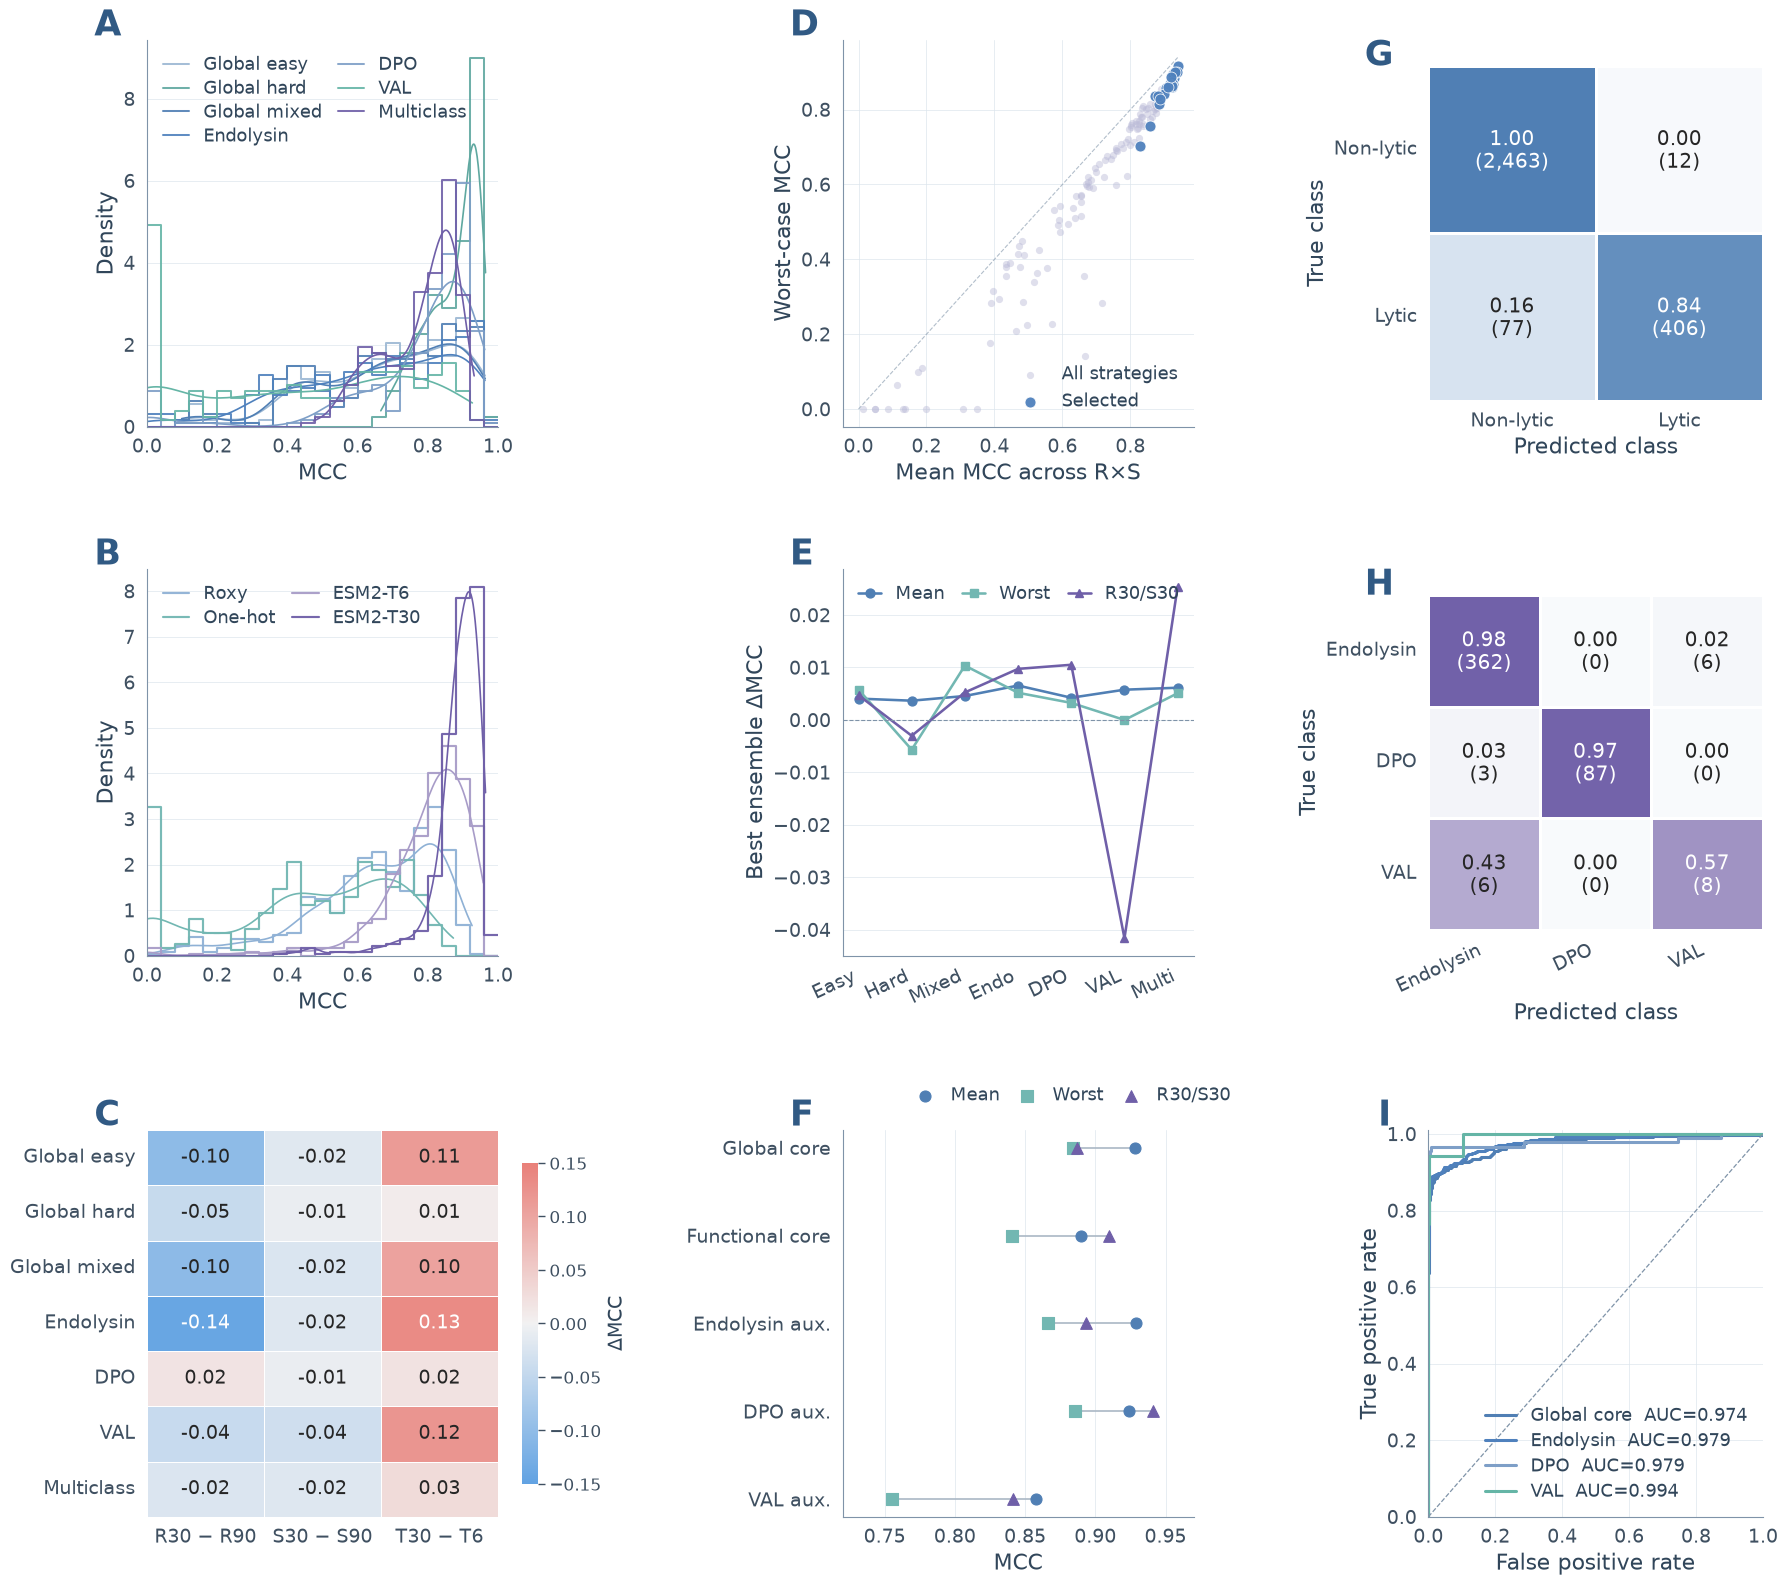

In [6]:
# -------------------------------------------------------------------------
# Build the full A–J panel
# -------------------------------------------------------------------------

fig = plt.figure(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
fig.get_layout_engine().set(w_pad=0.16, h_pad=0.17, wspace=0.10, hspace=0.10)
gs = fig.add_gridspec(
    nrows=3,
    ncols=3,
    width_ratios=[1.07, 1.07, 1.02],
    height_ratios=[1.0, 1.0, 1.0],
)

axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[1, 0])
axC = fig.add_subplot(gs[2, 0])

axE = fig.add_subplot(gs[0, 1])
axF = fig.add_subplot(gs[1, 1])
axG = fig.add_subplot(gs[2, 1])

# Final-model characterization in one dedicated column.
axH = fig.add_subplot(gs[0, 2])
axI = fig.add_subplot(gs[1, 2])
axJ = fig.add_subplot(gs[2, 2])

# =========================================================================
# A — performance distributions by task
# =========================================================================
bins = np.linspace(0.0, 1.0, 26)

for task in TASK_ORDER:
    block = supervised.loc[supervised["task"].eq(task), "mcc"].dropna()
    sns.histplot(
        block,
        bins=bins,
        stat="density",
        element="step",
        fill=False,
        kde=True,
        color=TASK_COLORS[task],
        linewidth=1.45,
        alpha=0.90,
        label=TASK_NAMES[task],
        ax=axA,
    )

axA.set_xlim(0, 1)
axA.set_xlabel("MCC")
axA.set_ylabel("Density")
axA.legend(frameon=False, ncol=2, loc="upper left", handlelength=1.5,
           fontsize=12.7, columnspacing=0.9, labelspacing=0.32)
clean_axis(axA, "y")
panel_letter(axA, "A")

# =========================================================================
# B — performance distributions by representation
# =========================================================================
for rep in REP_ORDER:
    block = supervised.loc[
        supervised["representation"].eq(rep), "mcc"
    ].dropna()
    sns.histplot(
        block,
        bins=bins,
        stat="density",
        element="step",
        fill=False,
        kde=True,
        color=REP_COLORS[rep],
        linewidth=1.55,
        alpha=0.95,
        label=REP_NAMES[rep],
        ax=axB,
    )

axB.set_xlim(0, 1)
axB.set_xlabel("MCC")
axB.set_ylabel("Density")
axB.legend(frameon=False, ncol=2, loc="upper left", handlelength=1.5,
           fontsize=12.7, columnspacing=0.95, labelspacing=0.34)
clean_axis(axB, "y")
panel_letter(axB, "B")

# =========================================================================
# C — generalization effects
# =========================================================================
abs_lim = float(np.nanmax(np.abs(geometry_plot.to_numpy())))
abs_lim = max(abs_lim, 0.15)

sns.heatmap(
    geometry_plot,
    cmap=DIVERGING_CMAP,
    center=0,
    vmin=-abs_lim,
    vmax=abs_lim,
    annot=True,
    annot_kws={"fontsize": HEATMAP_NUMBER_SIZE},
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "ΔMCC", "shrink": 0.83, "pad": 0.025, "fraction": 0.047},
    ax=axC,
)

axC.set_xlabel("")
axC.set_ylabel("")
axC.tick_params(axis="x", rotation=0)
axC.tick_params(axis="y", rotation=0)
cbar = axC.collections[0].colorbar
cbar.ax.tick_params(labelsize=COLORBAR_TICK_SIZE)
cbar.set_label("ΔMCC", fontsize=COLORBAR_LABEL_SIZE)
panel_letter(axC, "C")

# =========================================================================
# E — robustness selection space
# =========================================================================
not_selected = candidate_profiles.loc[~candidate_profiles["selected"]]
is_selected = candidate_profiles.loc[candidate_profiles["selected"]]

axE.scatter(
    not_selected["mean_mcc"],
    not_selected["worst_mcc"],
    s=27,
    color=COLORS["Unknown"],
    alpha=0.45,
    linewidth=0,
    label="All strategies",
)

axE.scatter(
    is_selected["mean_mcc"],
    is_selected["worst_mcc"],
    s=62,
    color=COLORS["P core"],
    alpha=0.95,
    edgecolor="white",
    linewidth=0.55,
    label="Selected",
    zorder=3,
)

lo = min(candidate_profiles["mean_mcc"].min(), candidate_profiles["worst_mcc"].min())
hi = max(candidate_profiles["mean_mcc"].max(), candidate_profiles["worst_mcc"].max())
axE.plot([lo, hi], [lo, hi], ls="--", lw=0.8, color="#7F93A8", alpha=0.60)

axE.set_xlabel("Mean MCC across R×S")
axE.set_ylabel("Worst-case MCC")
axE.legend(frameon=False, loc="lower right")
clean_axis(axE, "both")
panel_letter(axE, "D")

# =========================================================================
# F — ensemble gains
# =========================================================================
x = np.arange(len(TASK_ORDER))

axF.plot(
    x,
    ensemble_plot["max_mean_gain_vs_best_single"],
    marker="o",
    markersize=6.4,
    linewidth=1.85,
    color=COLORS["E2+E3 combined"],
    label="Mean",
)
axF.plot(
    x,
    ensemble_plot["max_worst_gain_vs_best_single"],
    marker="s",
    markersize=6.4,
    linewidth=1.85,
    color=COLORS["E3 physicochemical"],
    label="Worst",
)
axF.plot(
    x,
    ensemble_plot["max_strict_gain_vs_best_single"],
    marker="^",
    markersize=6.4,
    linewidth=1.85,
    color=COLORS["ESM2-T30"],
    label="R30/S30",
)

axF.axhline(0, color="#7F93A8", lw=0.8, ls="--")
axF.set_xticks(x)
axF.set_xticklabels(
    ["Easy", "Hard", "Mixed", "Endo", "DPO", "VAL", "Multi"],
    rotation=25,
    ha="right",
)
axF.set_ylabel("Best ensemble ΔMCC")
axF.set_xlabel("")
axF.legend(frameon=False, ncol=3, loc="upper left", fontsize=12.7,
           columnspacing=1.0, handlelength=1.3)
clean_axis(axF, "y")
panel_letter(axF, "E")

# =========================================================================
# G — frozen final recipes
# =========================================================================
y = np.arange(len(RECIPE_ORDER))

axG.scatter(
    recipes_plot["mean_mcc"], y,
    s=63, marker="o",
    color=COLORS["E2+E3 combined"],
    label="Mean", zorder=3,
)
axG.scatter(
    recipes_plot["worst_mcc"], y,
    s=63, marker="s",
    color=COLORS["E3 physicochemical"],
    label="Worst", zorder=3,
)
axG.scatter(
    recipes_plot["strict_mcc_R30S30"], y,
    s=70, marker="^",
    color=COLORS["ESM2-T30"],
    label="R30/S30", zorder=3,
)

for yi, task in enumerate(RECIPE_ORDER):
    vals = recipes_plot.loc[
        task, ["mean_mcc", "worst_mcc", "strict_mcc_R30S30"]
    ].astype(float).to_numpy()
    axG.plot(
        [vals.min(), vals.max()],
        [yi, yi],
        color="#AAB8C5",
        lw=1.2,
        zorder=1,
    )

axG.set_yticks(y)
axG.set_yticklabels([RECIPE_NAMES[t] for t in RECIPE_ORDER])
axG.invert_yaxis()
axG.set_xlim(0.72, 0.97)
axG.set_xlabel("MCC")
axG.set_ylabel("")
axG.legend(frameon=False, ncol=3, loc="lower right",
           bbox_to_anchor=(1.15, 1.025), fontsize=12.7,
           columnspacing=0.95, handlelength=1.25)
clean_axis(axG, "x")
panel_letter(axG, "F")

# =========================================================================
# H — binary confusion matrix: final global core, strict R30/S30
# =========================================================================
b_frac, b_count, b_annot = confusion_matrix_table(
    "global_mixed", "ensemble", ["0", "1"]
)

sns.heatmap(
    b_frac,
    cmap=BINARY_CMAP,
    vmin=0,
    vmax=1,
    annot=b_annot,
    annot_kws={"fontsize": CONFUSION_NUMBER_SIZE, "linespacing": 1.2},
    fmt="",
    square=True,
    linewidths=1.0,
    linecolor="white",
    cbar=False,
    ax=axH,
)

axH.set_xticklabels(["Non-lytic", "Lytic"], rotation=0)
axH.set_yticklabels(["Non-lytic", "Lytic"], rotation=0)
axH.set_xlabel("Predicted class")
axH.set_ylabel("True class")
panel_letter(axH, "G", x=-0.19)

# =========================================================================
# I — multiclass confusion matrix: final functional core, strict R30/S30
# =========================================================================
multi_classes = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

m_frac, m_count, m_annot = confusion_matrix_table(
    "multiclass_clean", "ensemble", multi_classes
)

sns.heatmap(
    m_frac,
    cmap=MULTICLASS_CMAP,
    vmin=0,
    vmax=1,
    annot=m_annot,
    annot_kws={"fontsize": CONFUSION_NUMBER_SIZE, "linespacing": 1.2},
    fmt="",
    square=True,
    linewidths=1.0,
    linecolor="white",
    cbar=False,
    ax=axI,
)

axI.set_xticklabels(["Endolysin", "DPO", "VAL"], rotation=25, ha="right")
axI.set_yticklabels(["Endolysin", "DPO", "VAL"], rotation=0)
axI.set_xlabel("Predicted class")
axI.set_ylabel("True class")
panel_letter(axI, "H", x=-0.19)

# =========================================================================
# J — combined ROC curves for final binary models
# =========================================================================
for task, variant in FINAL_BINARY_VARIANTS.items():
    block = binary_curves[
        binary_curves["task"].eq(task)
        & binary_curves["variant"].eq(variant)
        & binary_curves["curve"].eq("ROC")
    ].sort_values("x")

    auc = float(strict_metrics.loc[task, "final_roc_auc"])
    axJ.plot(
        block["x"],
        block["y"],
        lw=2.2,
        color=FINAL_BINARY_COLORS[task],
        label=f"{FINAL_BINARY_NAMES[task]}  AUC={auc:.3f}",
    )

axJ.plot([0, 1], [0, 1], ls="--", lw=0.9, color="#7F93A8")
axJ.set_xlim(0, 1)
axJ.set_ylim(0, 1.01)
axJ.set_xlabel("False positive rate")
axJ.set_ylabel("True positive rate")
axJ.legend(frameon=False, loc="lower right", fontsize=12.7,
           labelspacing=0.4, handlelength=1.8)
clean_axis(axJ, "both")
panel_letter(axJ, "I", x=-0.15, y=1.08)

# =========================================================================
# Export
# =========================================================================
OUTPUT_DIR = PROJECT_ROOT / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PNG_PATH = OUTPUT_DIR / "PhageLysClass_benchmark_panel.png"
PDF_PATH = OUTPUT_DIR / "PhageLysClass_benchmark_panel.pdf"

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

print(f"Saved PNG: {PNG_PATH}")
print(f"Saved PDF: {PDF_PATH}")

plt.show()